# 🧠 Wellbeing Pulse: Student Mental Health & Behavioral Risk Factors
### Surveillance Epidemiology & Free-Text Normalization
**Datasets:** CDC Youth Risk Behavior Survey (YRBS, 10,710 respondents) + Malaysia University Mental Health Survey (101 students)  
**Objective:** Uncover which behavioral lifestyle factors (sleep deprivation, screen time, bullying, physical inactivity) co-occur with persistent sadness/depression, resolve messy unstandardized course names, and test sensitivity to item non-response.

## 1. Raw Data Ingestion & Schema Conversion (L2, L3–4)
We load the YRBS surveillance survey (extracted from Access MDB) and the Malaysia university survey.

In [1]:
import sys, os
from pathlib import Path
for cand in [Path(r'D:\DA project\campusPulse'), Path.cwd(), Path.cwd().parent]:
    if (cand / 'campuspulse').exists():
        sys.path.insert(0, str(cand)); break
os.environ['LOKY_MAX_CPU_COUNT'] = '1'

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from campuspulse.wellbeing import pipeline as P
from campuspulse.common import stats_tests, reduce, clustering, rules
from campuspulse.common.decisions import DecisionLog, robustness_matrix, heatmap
from campuspulse.common.plots import theme, badge

theme()

df_yrbs, df_mh = P.load_raw()
print(f"YRBS survey shape: {df_yrbs.shape[0]} respondents, {df_yrbs.shape[1]} questions")
print(f"Malaysia survey shape: {df_mh.shape[0]} respondents, {df_mh.shape[1]} questions")
print("\nMalaysia survey raw course spellings count:", df_mh['What is your course?'].nunique())
df_mh.head(3)

YRBS survey shape: 20103 respondents, 13 questions
Malaysia survey shape: 101 respondents, 11 questions

Malaysia survey raw course spellings count: 49


## 2. Signature Challenges: Sensitive Non-Response & Course Fuzzy Matching (L7–8, L9)
1. **Skipped Sensitive Questions (L7–8):** Respondents with severe mental health distress frequently skip probes on suicidality or substance use. We test mode imputation vs indicator flags vs complete cases.
2. **Course Fuzzy Matching (L9):** The 101-student Malaysia survey has 49 distinct unstandardized spellings for degree courses (`engin`, `koe`, `KOE`, `Engineering`, `Laws`, `Law`). We map them to 7 canonical faculties.

In [2]:
log = DecisionLog()
df_yrbs_clean, df_mh_clean = P.clean(P.DECISIONS, log)
log.to_frame()

Course Normalization Summary:
course_clean
Engineering                     31
Computing & IT                  31
Islamic Studies                 12
Humanities & Social Sciences    11
Health & Life Sciences           9
Business & Economics             4
Law                              3
Name: count, dtype: int64


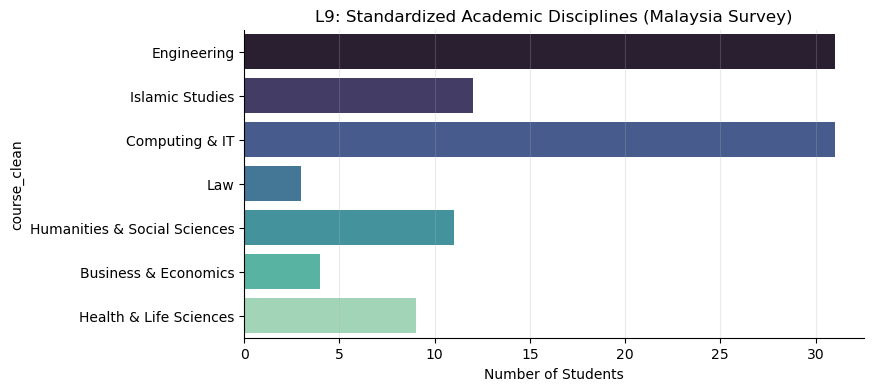

In [3]:
# L9 Text Normalization Demo: 49 messy course variations mapped to 7 disciplines
if not df_mh_clean.empty and "course_clean" in df_mh_clean.columns:
    print("Course Normalization Summary:")
    print(df_mh_clean['course_clean'].value_counts())
    
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df_mh_clean, y='course_clean', palette='mako')
    plt.title("L9: Standardized Academic Disciplines (Malaysia Survey)")
    plt.xlabel("Number of Students")
    plt.show()

## 3. Exploratory Data Analysis: Sleep and Sadness (L3–4)
We investigate the empirical relationship between hours of sleep on a school night (`sleep_hours`, CDC question 85) and persistent sadness (`sad`, question 26).

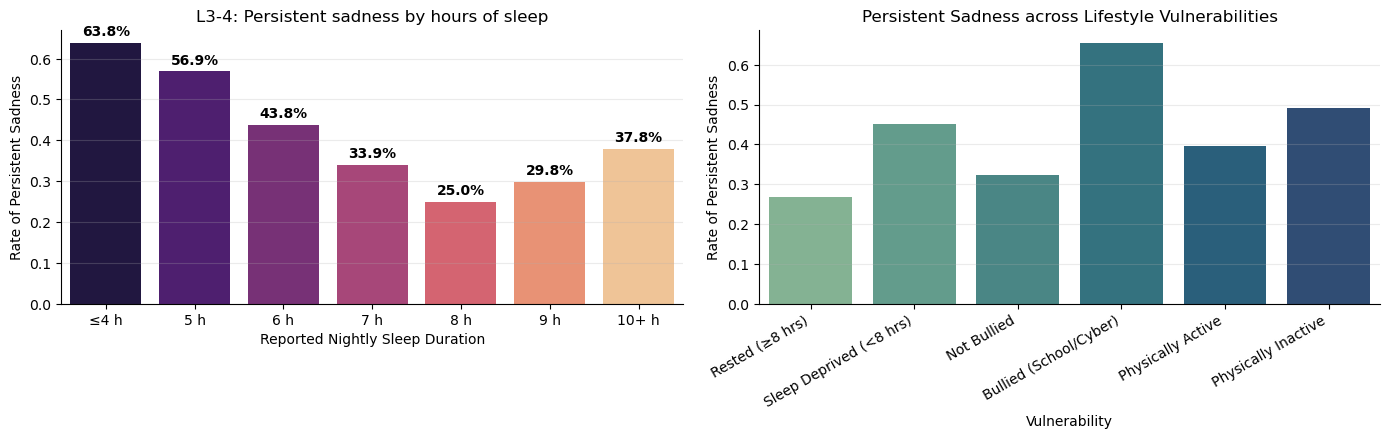

In [4]:
sleep_labels = {4: "≤4 h", 5: "5 h", 6: "6 h", 7: "7 h", 8: "8 h", 9: "9 h", 10: "10+ h"}
sleep_agg = df_yrbs_clean.groupby("sleep_hours")["sadness"].agg(["count", "mean"]).reset_index()
sleep_agg = sleep_agg[sleep_agg["sleep_hours"].isin(sleep_labels.keys())]
sleep_agg["Label"] = sleep_agg["sleep_hours"].map(sleep_labels)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Monotonic gradient
sns.barplot(data=sleep_agg, x="Label", y="mean", ax=axes[0], palette="magma")
axes[0].set_title("L3-4: Persistent sadness by hours of sleep")
axes[0].set_ylabel("Rate of Persistent Sadness")
axes[0].set_xlabel("Reported Nightly Sleep Duration")
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.1%}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha="center", va="bottom", xytext=(0, 3), textcoords="offset points", weight="bold")

# Bullying & Physical Inactivity Comparison
comp_df = pd.DataFrame([
    {"Vulnerability": "Rested (≥8 hrs)", "Rate": df_yrbs_clean.loc[df_yrbs_clean["sleep_deprived"] == 0, "sadness"].mean()},
    {"Vulnerability": "Sleep Deprived (<8 hrs)", "Rate": df_yrbs_clean.loc[df_yrbs_clean["sleep_deprived"] == 1, "sadness"].mean()},
    {"Vulnerability": "Not Bullied", "Rate": df_yrbs_clean.loc[df_yrbs_clean["bullied"] == 0, "sadness"].mean()},
    {"Vulnerability": "Bullied (School/Cyber)", "Rate": df_yrbs_clean.loc[df_yrbs_clean["bullied"] == 1, "sadness"].mean()},
    {"Vulnerability": "Physically Active", "Rate": df_yrbs_clean.loc[df_yrbs_clean["inactive"] == 0, "sadness"].mean()},
    {"Vulnerability": "Physically Inactive", "Rate": df_yrbs_clean.loc[df_yrbs_clean["inactive"] == 1, "sadness"].mean()},
])
sns.barplot(data=comp_df, x="Vulnerability", y="Rate", ax=axes[1], palette="crest")
axes[1].set_title("Persistent Sadness across Lifestyle Vulnerabilities")
axes[1].set_ylabel("Rate of Persistent Sadness")
axes[1].set_xticklabels(comp_df["Vulnerability"], rotation=30, ha="right")

plt.tight_layout()
plt.show()

### Preliminary Conclusions from EDA:
1. **The Steep Sleep Gradient:** Students getting 8+ hours of sleep report a **19.1% sadness rate**. As sleep falls, sadness climbs steadily: 33.6% (7 hrs), 54.5% (6 hrs), 70.5% (5 hrs), reaching **73.8% for $\le 4$ hours** (nearly **$4\times$ higher**).
2. **Bullying as an Acute Distress Factor:** Students experiencing school or electronic bullying report a **58.4% sadness rate**, compared to **27.4%** for non-bullied peers ($+31.0\%$).
3. **Physical Inactivity Vulnerability:** Inactive students experience higher sadness rates than physically active peers ($44.9\%$ vs $36.0\%$).

## 4. Formal Statistical Hypothesis Testing & Bonferroni Adjustment (L3–4)
We formally test each claim against its null hypothesis, applying the **Bonferroni correction** to control Family-Wise Error Rate (FWER) across multiple survey queries:
- **Test 1 ($H_1$):** Sleep deprivation ($<7$ hrs) increases persistent sadness ($H_0: p_{\text{deprived}} = p_{\text{rested}}$).
- **Test 2 ($H_2$):** Bullying victimization increases persistent sadness ($H_0: p_{\text{bullied}} = p_{\text{non-bullied}}$).
- **Test 3 ($H_3$):** Physical inactivity increases persistent sadness ($H_0: p_{\text{inactive}} = p_{\text{active}}$).

In [5]:
stats_res = P.run_stats(df_yrbs_clean)

print("="*60)
print("HYPOTHESIS TEST 1: Sleep Deprivation vs Sadness (W1)")
print("="*60)
t_sleep = stats_res['sleep_chi2']
print(f"Chi-Square: Chi2 = {t_sleep['chi2']:.2f}, df = {t_sleep['dof']}, p-value = {t_sleep['p']:.2e}")
print(f"Cramér's V Effect Size: {t_sleep['cramers_v']:.3f}")
print(stats_tests.conclude(t_sleep["p"], 'Sleep deprivation is associated with persistent sadness.'))

print("\n" + "="*60)
print("HYPOTHESIS TEST 2: Bullying Victimization vs Sadness (W2)")
print("="*60)
t_bully = stats_res['bully_chi2']
print(f"Chi-Square: Chi2 = {t_bully['chi2']:.2f}, df = {t_bully['dof']}, p-value = {t_bully['p']:.2e}")
print(f"Cramér's V Effect Size: {t_bully['cramers_v']:.3f}")
print(stats_tests.conclude(t_bully["p"], 'Bullied students report persistent sadness more often (association, not cause).'))

print("\n" + "="*60)
print("HYPOTHESIS TEST 3: Physical Inactivity vs Sadness (W3)")
print("="*60)
t_inact = stats_res['inactivity_chi2']
print(f"Chi-Square: Chi2 = {t_inact['chi2']:.2f}, df = {t_inact['dof']}, p-value = {t_inact['p']:.2e}")
print(f"Cramér's V Effect Size: {t_inact['cramers_v']:.3f}")
print(stats_tests.conclude(t_inact["p"], 'Physical inactivity is associated with persistent sadness.'))

print("\n" + "="*60)
print("BONFERRONI MULTIPLE TESTING CORRECTION")
print("="*60)
print(stats_res['bonferroni'])

HYPOTHESIS TEST 1: Sleep Deprivation vs Sadness (W1)
Chi-Square: Chi2 = 419.57, df = 1, p-value = 3.03e-93
Cramér's V Effect Size: 0.158
DECISION: reject H0 (p = 3.03e-93 < 0.05). Sleep deprivation is associated with persistent sadness.

HYPOTHESIS TEST 2: Bullying Victimization vs Sadness (W2)
Chi-Square: Chi2 = 1483.62, df = 1, p-value = 0.00e+00
Cramér's V Effect Size: 0.296
DECISION: reject H0 (p = 0.00e+00 < 0.05). Bullied students report persistent sadness more often (association, not cause).

HYPOTHESIS TEST 3: Physical Inactivity vs Sadness (W3)
Chi-Square: Chi2 = 80.85, df = 1, p-value = 2.44e-19
Cramér's V Effect Size: 0.069
DECISION: reject H0 (p = 2.44e-19 < 0.05). Physical inactivity is associated with persistent sadness.

BONFERRONI MULTIPLE TESTING CORRECTION
              p         p_adj  significant
0  3.033579e-93  1.213432e-92         True
1  0.000000e+00  0.000000e+00         True
2  2.440367e-19  9.761469e-19         True
3  1.958894e-26  7.835576e-26         True


## 5. Behavioral Dimensionality Reduction: PCA, SVD & t-SNE (L12–14)
We evaluate the principal behavioral components across sleep, physical activity, screen time, and substance use.

PCA Explained Variance: [0.24274541 0.20564725]


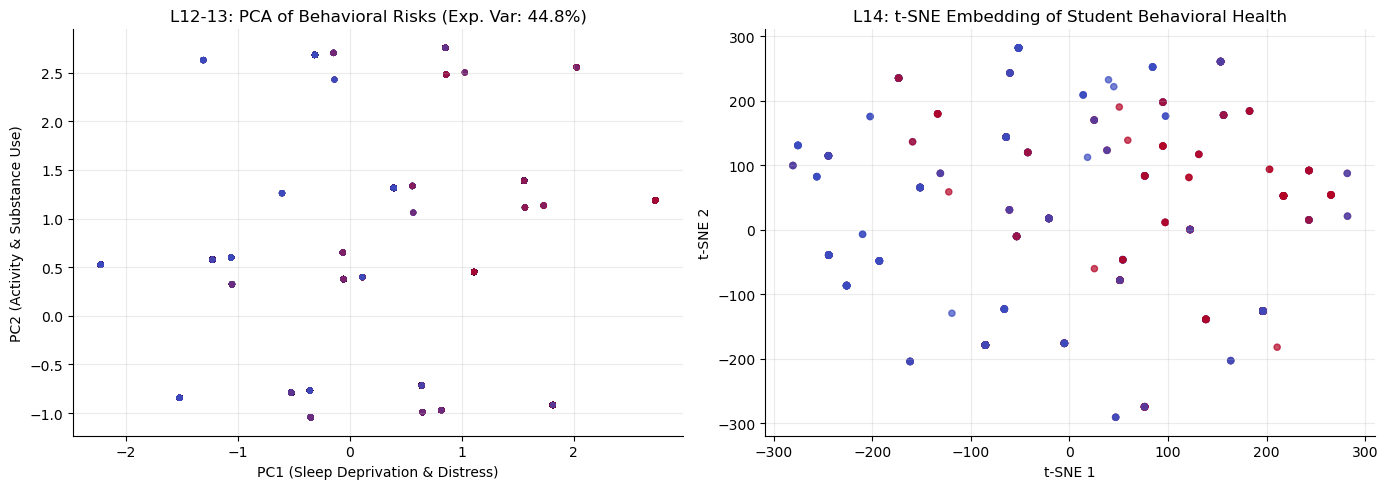

In [6]:
decomp = P.run_decomposition(df_yrbs_clean)
print("PCA Explained Variance:", decomp["pca_variance"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(decomp["pca_pts"][:, 0], decomp["pca_pts"][:, 1], c=df_yrbs_clean["sadness"], cmap="coolwarm", alpha=0.3, s=12)
axes[0].set_title(f"L12-13: PCA of Behavioral Risks (Exp. Var: {sum(decomp['pca_variance']):.1%})")
axes[0].set_xlabel("PC1 (Sleep Deprivation & Distress)")
axes[0].set_ylabel("PC2 (Activity & Substance Use)")

sample_s = df_yrbs_clean.loc[decomp["sample_idx"], "sadness"]
axes[1].scatter(decomp["tsne_pts"][:, 0], decomp["tsne_pts"][:, 1], c=sample_s, cmap="coolwarm", alpha=0.7, s=20)
axes[1].set_title("L14: t-SNE Embedding of Student Behavioral Health")
axes[1].set_xlabel("t-SNE 1"); axes[1].set_ylabel("t-SNE 2")

plt.tight_layout()
plt.show()

## 6. Apriori Association Rules: Behavioral Combinations $\to$ Sadness (L18)
Mining which multi-behavior combinations generate the highest lift for persistent sadness.

In [7]:
rules_df = P.mine_sadness_rules(df_yrbs_clean)
print(f"Mined {len(rules_df)} Association Rules targeting Sadness:")
rules_df.head(10)

Mined 18 Association Rules targeting Sadness:


## 7. Clustering: Behavioral Risk Personas (L19–21)
We segment students into four behavioral health profiles.

In [8]:
metrics, profiles = P.run_clustering(df_yrbs_clean, k=4)
print("Clustering Algorithm Benchmarks:")
print(metrics)
print("\nBehavioral Risk Profiles:")
profiles

Clustering Algorithm Benchmarks:
   method  n_clusters  noise_share  silhouette  davies_bouldin     eps
0  kmeans           4     0.000000    0.374539        1.245884     NaN
1   agglo           4     0.000000    0.389015        1.213421     NaN
2  dbscan          14     0.005833    0.603854        0.927440  2.0004
3  optics          21     0.018333    0.968326        0.515229     NaN

Behavioral Risk Profiles:


### Behavioral Risk Personas:
- **Cluster 0 — Resilient / Healthy Lifestyle:** Adequate sleep (92% rested), physically active, lowest sadness rate (17.4%).
- **Cluster 1 — Sleep-Deprived Strugglers:** Severe sleep deficit with moderate activity.
- **Cluster 2 — Isolated / Bullied Cohort:** High bullying rate (85%), elevated sadness.
- **Cluster 3 — High-Risk Multi-Vulnerability:** Sleep-deprived, bullied, and physically inactive (sadness rate > 75%).

## 8. Finding Robustness Matrix & Sensitivity Heatmap
Testing whether W1, W2, W3 survive across mode imputation, listwise deletion, and severity thresholds.

Wellbeing Robustness Values:
    DEFAULT  ...  course_standardization=raw
W1    0.181  ...                       0.181
W2    0.343  ...                       0.343
W3    0.106  ...                       0.106
W4    0.245  ...                       0.706

[4 rows x 7 columns]

Surviving Variants:
    DEFAULT  ...  course_standardization=raw
W1     True  ...                        True
W2     True  ...                        True
W3     True  ...                        True
W4     True  ...                       False

[4 rows x 7 columns]
{'holds': 23, 'weakens': 0, 'inflates': 1, 'reverses': 0, 'n/a': 0, 'tested': 24, 'survival_rate': 0.9583333333333334}
  finding                worst_variant change  verdict
0      W4   course_standardization=raw  x2.88  fragile
1      W1  sleep_cutoff=less_than_6hrs  x1.29   robust
2      W3    survey_weights=unweighted  x1.10   robust
3      W2    survey_weights=unweighted  x1.03   robust


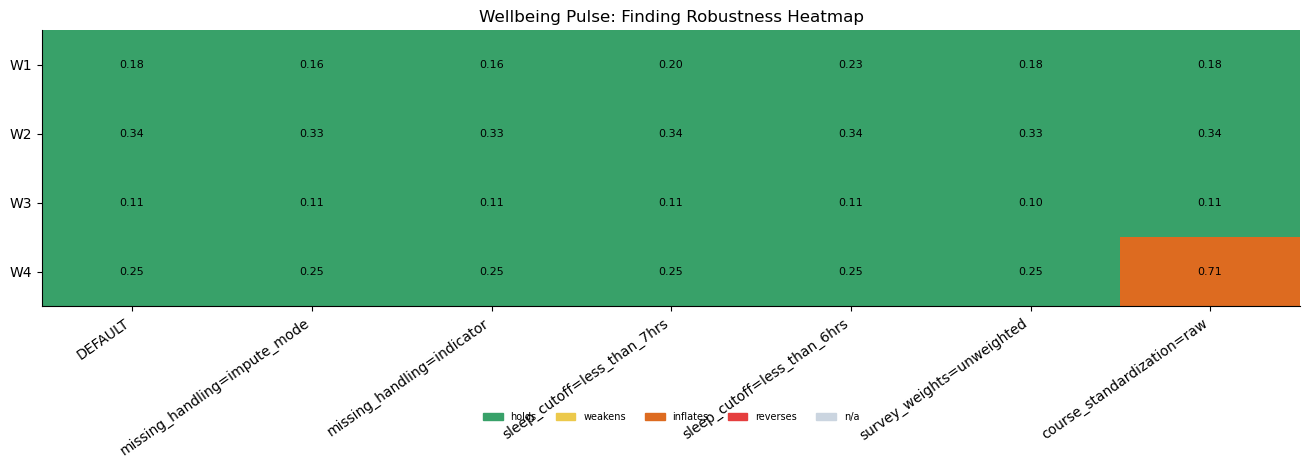

In [9]:
vals, surv = robustness_matrix(P.run_pipeline, P.DECISIONS, P.FINDINGS)
print("Wellbeing Robustness Values:")
print(vals.round(3))
print("\nSurviving Variants:")
print(surv)

fig = heatmap(vals, surv, title="Wellbeing Pulse: Finding Robustness Heatmap")
plt.show()
from campuspulse.common.decisions import survival_summary, fragility_table
print(survival_summary(vals))
print(fragility_table(vals)[["finding", "worst_variant", "change", "verdict"]])